# HyDeCoFfEE: RBF Surrogate Model

In the previous notebook we simulated 100 representative days of the Santoña
estuary with SFINCS and compressed their flood maps with **PCA**. Now we build
the surrogate model: a **Radial Basis Function (RBF)** interpolation relates
the daily forcing to the principal components, so that the flood map of any
new day is obtained without running SFINCS:

**forcing (`TWL`, `Q`, `precip_acum`) → RBF → PCs → inverse PCA → water level
→ water level − DEM → flood map**

> **Inputs:** the PCA model and the simulated scenarios (`export/`), their
> SFINCS results (`cases/`) and the DEM (`templates/`), all from
> `01_SFINCS_wrapper.ipynb`. Set `USE_PRETRAINED = True` to use instead the
> ones we provide in `pretrained/`.
>
> **Output:** the RBF model, `export/rbf_model.pkl`.

In [1]:
import logging
import os
import os.path as op
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from bluemath_tk.core.io import load_model
from bluemath_tk.interpolation.rbf import RBF
from sklearn.model_selection import KFold
from utils.plotting import plot_comparison, plot_output_cases
from utils.postprocessing import water_level_cases, water_level_to_depth
from utils.reconstruction import pcs_to_water_level

# Hide warnings and log messages (errors are still shown)
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)

# True: use the models and SFINCS results we provide (pretrained/)
# False: use yours, from 01_SFINCS_wrapper.ipynb (export/, cases/, templates/)
USE_PRETRAINED = False

root_dir = op.abspath("")
export_dir = op.join(root_dir, "export")
os.makedirs(export_dir, exist_ok=True)

if USE_PRETRAINED:
    model_dir = op.join(root_dir, "pretrained")
    dem_path = op.join(model_dir, "dem_santona_utm.tif")
else:
    model_dir = export_dir
    dem_path = op.join(root_dir, "templates", "dem_santona_utm.tif")

dep_hr = xr.open_dataset(dem_path)

variables = ["TWL", "Q", "precip_acum"]

pca = load_model(op.join(model_dir, "pca_model.pkl"))
df_inputs = pd.read_pickle(op.join(model_dir, "mda_centroids.pkl"))[variables]
df_pcs = pca.pcs_df

print(f"{len(df_inputs)} simulated scenarios, {df_pcs.shape[1]} principal components")

100 simulated scenarios, 8 principal components


## 1. RBF interpolation

The RBF interpolates each PC as a function of the three forcing variables,
using the 100 SFINCS scenarios as training data.

In [35]:
rbf = RBF()
rbf.fit(subset_data=df_inputs, target_data=df_pcs)

rbf.save_model(model_path=op.join(export_dir, "rbf_model.pkl"))

## 2. k-fold cross-validation: how many SFINCS simulations do we need?

To know how well the surrogate predicts **days it has never seen**, we split
the 100 scenarios into **5 folds**. For each fold, we fit the RBF without the
20 scenarios of the fold and predict them, so in the end every scenario has
been predicted by a model that did not use it.

In each fold we fit the RBF with an increasing number **N** of training
scenarios (the first ones selected by the MDA, up to the 80 available) and
predict always the same left-out scenarios. Plotting the error against N
shows whether more SFINCS simulations would still improve the surrogate.

The error is the RMSE between the RBF and SFINCS maximum water depth on the
20 m DEM.

> ℹ️ Only the RBF is refitted: the PCA patterns are those of the 100 scenarios.

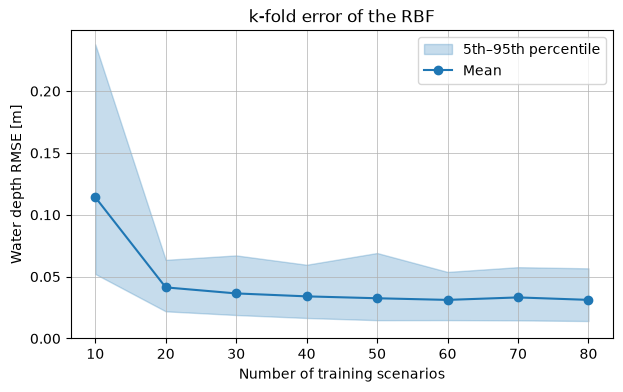

In [38]:
if USE_PRETRAINED:
    water_levels = xr.open_dataset(op.join(model_dir, "sfincs_water_levels.nc"))
else:
    water_levels = water_level_cases(
        cases_dir=op.join(root_dir, "cases"), n_cases=len(df_inputs)
    )
maps_sfincs = water_level_to_depth(water_levels["zs"], dep_hr)

kfold = KFold(n_splits=5, shuffle=True, random_state=0)
n_train_list = [10, 20, 30, 40, 50, 60, 70, 80]
rmse = {}

for n_train in n_train_list:
    pcs_cv = pd.DataFrame(index=df_pcs.index, columns=df_pcs.columns, dtype=float)

    for train, test in kfold.split(df_inputs):
        train = np.sort(train)[:n_train]  # first scenarios selected by the MDA
        rbf_fold = RBF()
        rbf_fold.fit(subset_data=df_inputs.iloc[train], target_data=df_pcs.iloc[train])
        pcs_cv.iloc[test] = rbf_fold.predict(df_inputs.iloc[test]).values

    maps_rbf = water_level_to_depth(pcs_to_water_level(pca, pcs_cv), dep_hr)
    rmse[n_train] = np.sqrt(((maps_rbf - maps_sfincs) ** 2).mean(dim=["x", "y"])).values

rmse = pd.DataFrame(rmse)  # rows: scenarios, columns: number of training scenarios

fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(
    rmse.columns,
    rmse.quantile(0.05),
    rmse.quantile(0.95),
    color="tab:blue",
    alpha=0.25,
    label="5th–95th percentile",
)
ax.plot(rmse.columns, rmse.mean(), "o-", c="tab:blue", label="Mean")
ax.set(
    xlabel="Number of training scenarios",
    ylabel="Water depth RMSE [m]",
    title="k-fold error of the RBF",
    ylim=(0, None),
)
ax.grid(lw=0.5)
ax.legend()
plt.show()

Let's compare the SFINCS and RBF maps (with all the 80 training scenarios of
each fold) of the scenarios with the **largest** and the **median** errors:

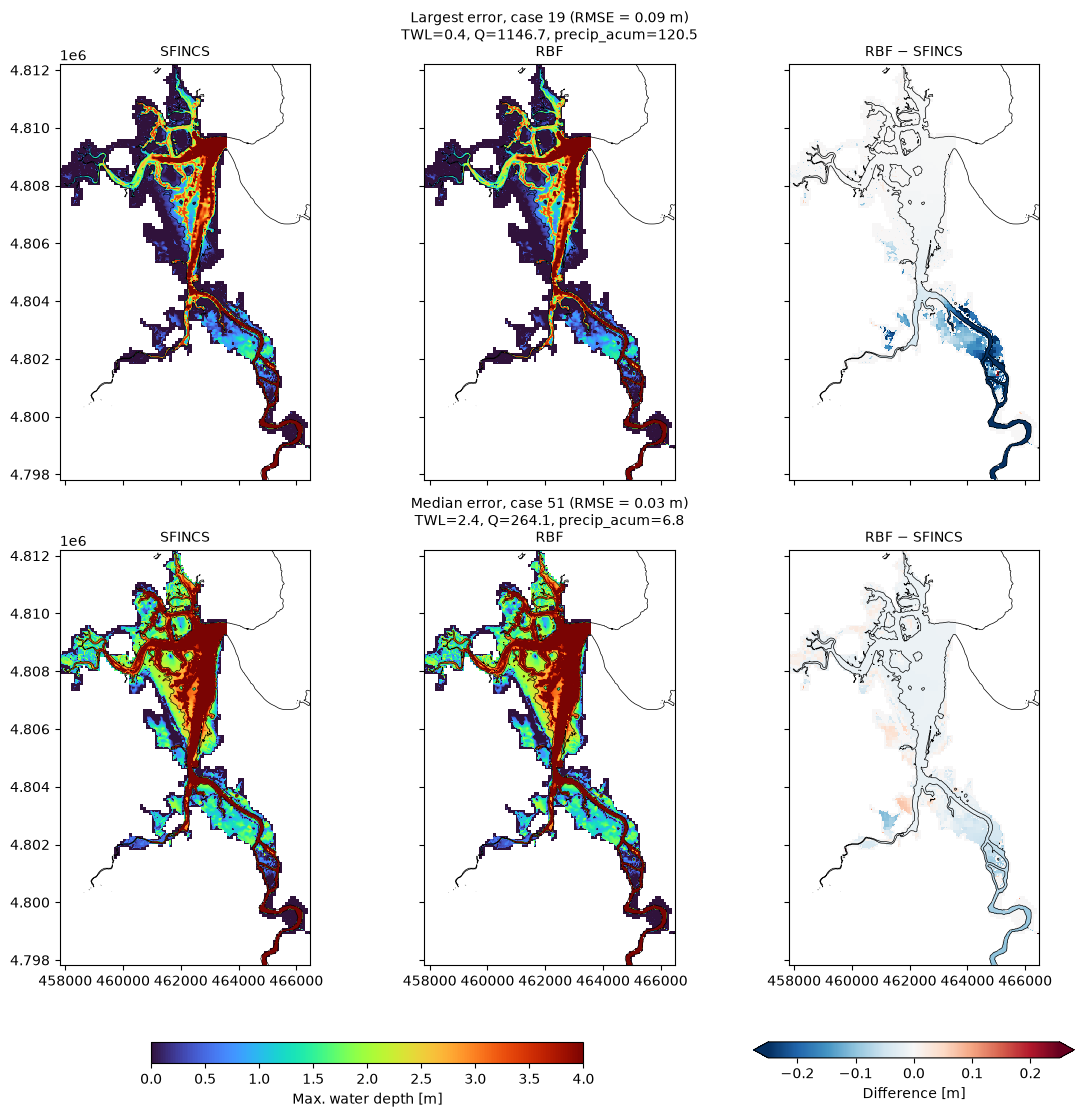

In [39]:
rmse_all = rmse[n_train_list[-1]]
cases = [int(rmse_all.idxmax()), int(rmse_all.sort_values().index[len(rmse_all) // 2])]

titles = [
    f"{label}, case {case} (RMSE = {rmse_all[case]:.2f} m)\n"
    + ", ".join(f"{v}={df_inputs[v].iloc[case]:.1f}" for v in variables)
    for label, case in zip(["Largest error", "Median error"], cases)
]

fig, axes = plot_comparison(
    [maps_sfincs.isel(case_num=case) for case in cases],
    [maps_rbf.isel(case_num=case) for case in cases],
    dep_hr,
    titles=titles,
)
plt.show()

> 💬 **Discussion:** For which scenarios is the surrogate worse? How would you
> improve it (more SFINCS simulations, another kernel, fewer PCs...)?

## 3. Using the surrogate

The fitted RBF gives the flood map of any combination of drivers within the
training range in a fraction of a second. For example:

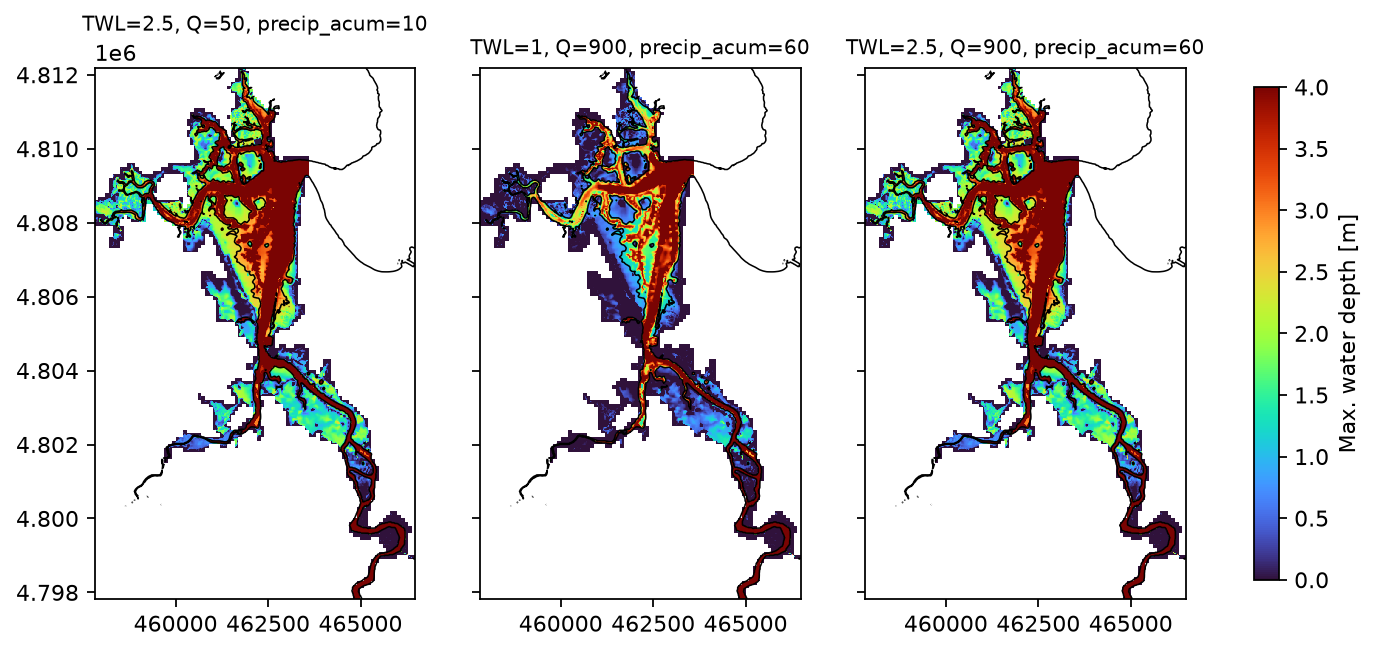

In [40]:
new_days = pd.DataFrame(
    {
        "TWL": [2.5, 1.0, 2.5],
        "Q": [50.0, 900.0, 900.0],
        "precip_acum": [10.0, 60.0, 60.0],
    }
)

maps_new = water_level_to_depth(pcs_to_water_level(pca, rbf.predict(new_days)), dep_hr)

fig, axes = plot_output_cases(
    list(maps_new),
    dep_hr,
    cmap="turbo",
    vmin=0,
    vmax=4,
    label="Max. water depth [m]",
    titles=[
        ", ".join(f"{v}={row[v]:g}" for v in variables)
        for _, row in new_days.iterrows()
    ],
    figsize=(11, 5),
)
plt.show()

## Summary

We built an **RBF surrogate** that relates the daily `TWL`, `Q` and
`precip_acum` to the PCs of the SFINCS flood maps, checked its skill with a
**5-fold cross-validation**, and saved it in `export/rbf_model.pkl`. It can now
be used to obtain the flood map of the Santoña estuary for any day without
running SFINCS. In `04_Flood_climate.ipynb` we use it to
turn thousands of emulated days into flood statistics.